In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Audience Segmentation Analysis Started!")


Audience Segmentation Analysis Started!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Dataset.csv to Dataset.csv


In [3]:
df = pd.read_csv('Dataset.csv')

print("Dataset Shape:", df.shape)

print("\nRating Distribution:")
print(df['rating'].value_counts())

print("\nContent Type and Rating:")
print(df[['title', 'type', 'rating']].head(15))

Dataset Shape: (8790, 10)

Rating Distribution:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Content Type and Rating:
                               title     type rating
0               Dick Johnson Is Dead    Movie  PG-13
1                          Ganglands  TV Show  TV-MA
2                      Midnight Mass  TV Show  TV-MA
3   Confessions of an Invisible Girl    Movie  TV-PG
4                            Sankofa    Movie  TV-MA
5      The Great British Baking Show  TV Show  TV-14
6                       The Starling    Movie  PG-13
7    Motu Patlu in the Game of Zones    Movie  TV-Y7
8                       Je Suis Karl    Movie  TV-MA
9           Motu Patlu in Wonderland    Movie  TV-Y7
10    Motu Patlu: Deep Sea Adventure    Movie  TV-Y7
11          Motu Pa

In [4]:
print("Missing Rating Values:")
print(df['rating'].isnull().sum())

print("\nUnique Rating Categories:")
print(df['rating'].unique())

Missing Rating Values:
0

Unique Rating Categories:
['PG-13' 'TV-MA' 'TV-PG' 'TV-14' 'TV-Y7' 'TV-Y' 'PG' 'TV-G' 'R' 'G'
 'NC-17' 'NR' 'TV-Y7-FV' 'UR']


In [5]:

# Audience Rating Segmentation

rating_df = df.copy()

rating_df['rating'] = rating_df['rating'].fillna('Not Rated')

rating_distribution = rating_df['rating'].value_counts()

print("Audience Rating Distribution")
print("--------------------------------")

print(rating_distribution)


Audience Rating Distribution
--------------------------------
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


In [6]:

# Top 5 Audience Rating Categories

top_ratings = rating_distribution.head(5)

print("Top 5 Audience Categories:")
print(top_ratings)

print("\nMost Dominant Audience Category:")
print(top_ratings.index[0])

print("Number of Titles:", top_ratings.iloc[0])


Top 5 Audience Categories:
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
Name: count, dtype: int64

Most Dominant Audience Category:
TV-MA
Number of Titles: 3205


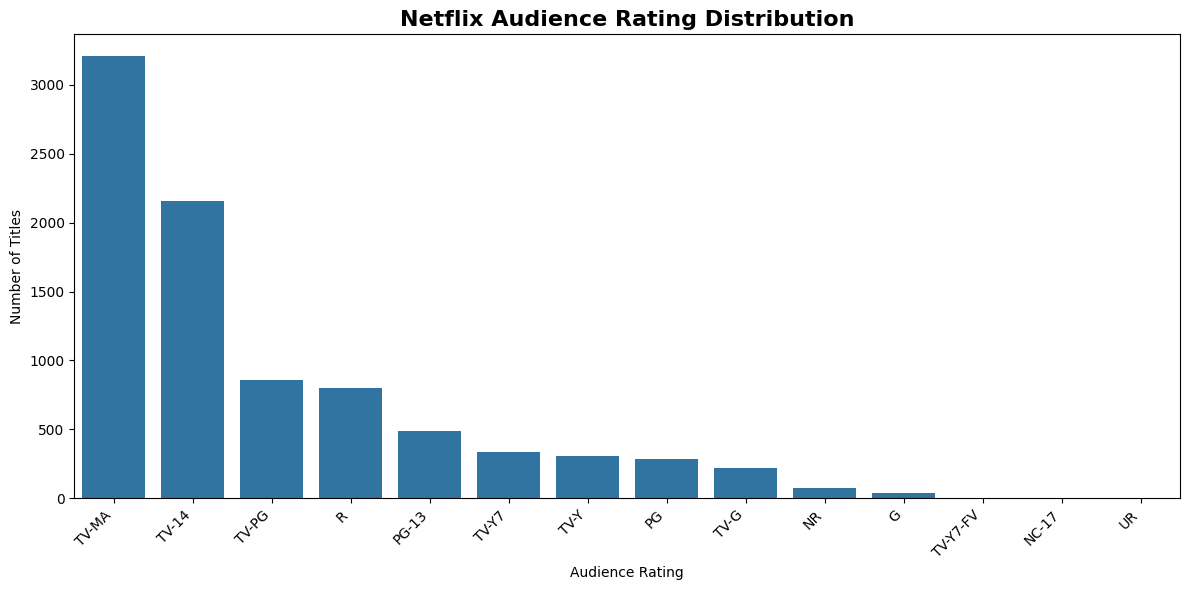

In [7]:

plt.figure(figsize=(12, 6))

sns.barplot(
    x=rating_distribution.index,
    y=rating_distribution.values
)

plt.title("Netflix Audience Rating Distribution",
          fontsize=16, fontweight='bold')

plt.xlabel("Audience Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig("audience_rating_distribution.png", dpi=300)
plt.show()


Movies vs TV Shows by Audience Rating


type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,730
TV-G,126,94
TV-MA,2062,1143


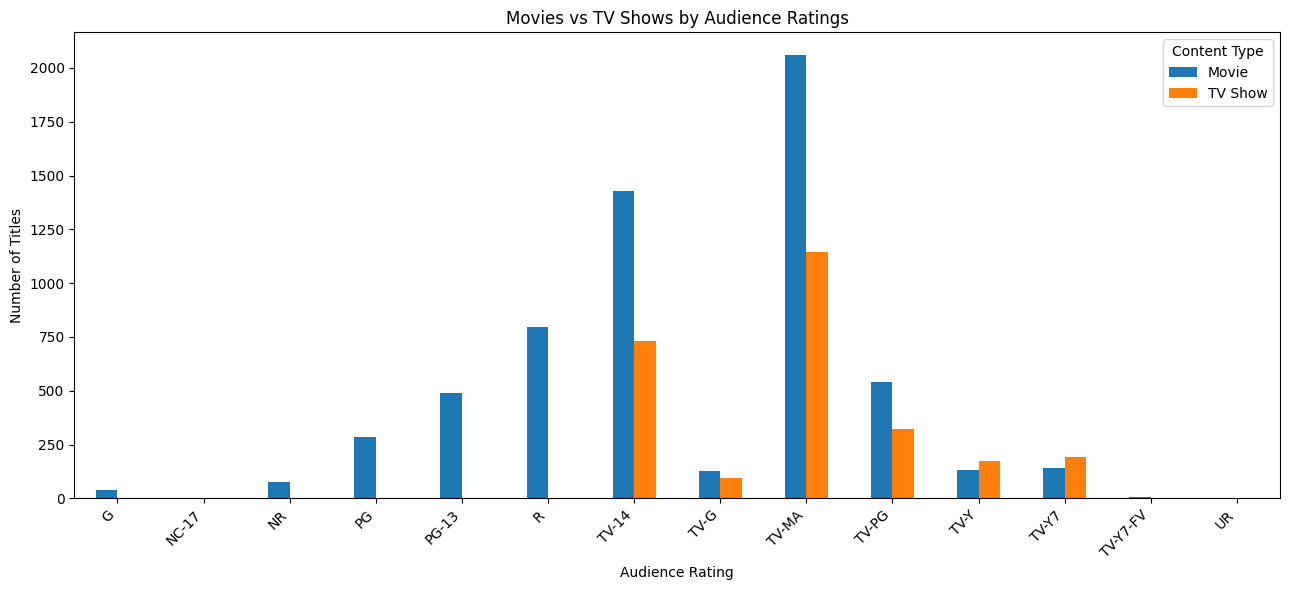

In [8]:

rating_comparison = pd.crosstab(
    rating_df['rating'],
    rating_df['type']
)

print("Movies vs TV Shows by Audience Rating")
display(rating_comparison)

rating_comparison.plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title("Movies vs TV Shows by Audience Ratings")
plt.xlabel("Audience Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Content Type")
plt.tight_layout()

plt.savefig("rating_content_comparison.png", dpi=300)
plt.show()


In [9]:

# Audience-Focused Business Insights

print("=" * 60)
print("NETFLIX AUDIENCE SEGMENTATION - BUSINESS INSIGHTS")
print("=" * 60)

# Identify dominant rating
dominant_rating = rating_distribution.index[0]
dominant_count = rating_distribution.iloc[0]

print(f"\n1. Dominant Audience Category: {dominant_rating}")
print(f"   Total Titles: {dominant_count:,}")

# Compare Movies and TV Shows
print("\n2. Content Type Distribution by Rating:")
display(rating_comparison)

# Calculate percentage distribution
rating_percentage = pd.crosstab(
    rating_df['rating'],
    rating_df['type'],
    normalize='columns'
) * 100

print("\n3. Rating Percentage by Content Type:")
display(rating_percentage.round(2))

print("\n4. Business Recommendations:")
print("- Study the most common audience rating categories.")
print("- Compare rating patterns between Movies and TV Shows.")
print("- Develop content strategies for different audience groups.")
print("- Identify less represented rating categories.")
print("- Consider audience ratings when planning future content.")

print("\nAnalysis Completed!")
print("=" * 60)


NETFLIX AUDIENCE SEGMENTATION - BUSINESS INSIGHTS

1. Dominant Audience Category: TV-MA
   Total Titles: 3,205

2. Content Type Distribution by Rating:


type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,730
TV-G,126,94
TV-MA,2062,1143



3. Rating Percentage by Content Type:


type,Movie,TV Show
rating,,
G,0.67,0.00
NC-17,0.05,0.00
NR,1.22,0.15
PG,4.68,0.00
PG-13,8.00,0.00
R,13.01,0.08
TV-14,23.29,27.40
TV-G,2.06,3.53
TV-MA,33.66,42.91



4. Business Recommendations:
- Study the most common audience rating categories.
- Compare rating patterns between Movies and TV Shows.
- Develop content strategies for different audience groups.
- Identify less represented rating categories.
- Consider audience ratings when planning future content.

Analysis Completed!


In [10]:

# Export Audience Segmentation Results

rating_distribution.to_csv(
    "Netflix_Audience_Rating_Summary.csv"
)

rating_comparison.to_csv(
    "Netflix_Rating_Content_Comparison.csv"
)

rating_percentage.to_csv(
    "Netflix_Rating_Percentage_Analysis.csv"
)

print("All analysis files exported successfully!")


All analysis files exported successfully!


In [11]:
from google.colab import files

files.download("audience_rating_distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
files.download("rating_content_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
files.download("Netflix_Audience_Rating_Summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
files.download("Netflix_Rating_Content_Comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
files.download("Netflix_Rating_Percentage_Analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>